In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
import math
wr.filterwarnings('ignore')

   nregistro                                             nombre  \
0      59082  ACUPREL 20 mg COMPRIMIDOS RECUBIERTOS CON PELI...   
1      61710  ACUPREL 40 mg COMPRIMIDOS RECUBIERTOS CON PELI...   
2      59081  ACUPREL 5 mg COMPRIMIDOS RECUBIERTOS CON PELICULA   
3      39059  ALDACTONE 25 mg COMPRIMIDOS RECUBIERTOS CON PE...   
4      68761            AMLODIPINO SANDOZ 10 mg COMPRIMIDOS EFG   

                 pactivos                labtitular        labcomercializador  \
0               QUINAPRIL               Pfizer S.L.               Pfizer S.L.   
1  QUINAPRIL HIDROCLORURO               Pfizer S.L.               Pfizer S.L.   
2               QUINAPRIL               Pfizer S.L.               Pfizer S.L.   
3         ESPIRONOLACTONA               Pfizer S.L.               Pfizer S.L.   
4     AMLODIPINO BESILATO  Sandoz Farmaceutica S.A.  Sandoz Farmaceutica S.A.   

       cn                  dosis forma_farmaceutica_simplificada  \
0  725150                  20 mg          

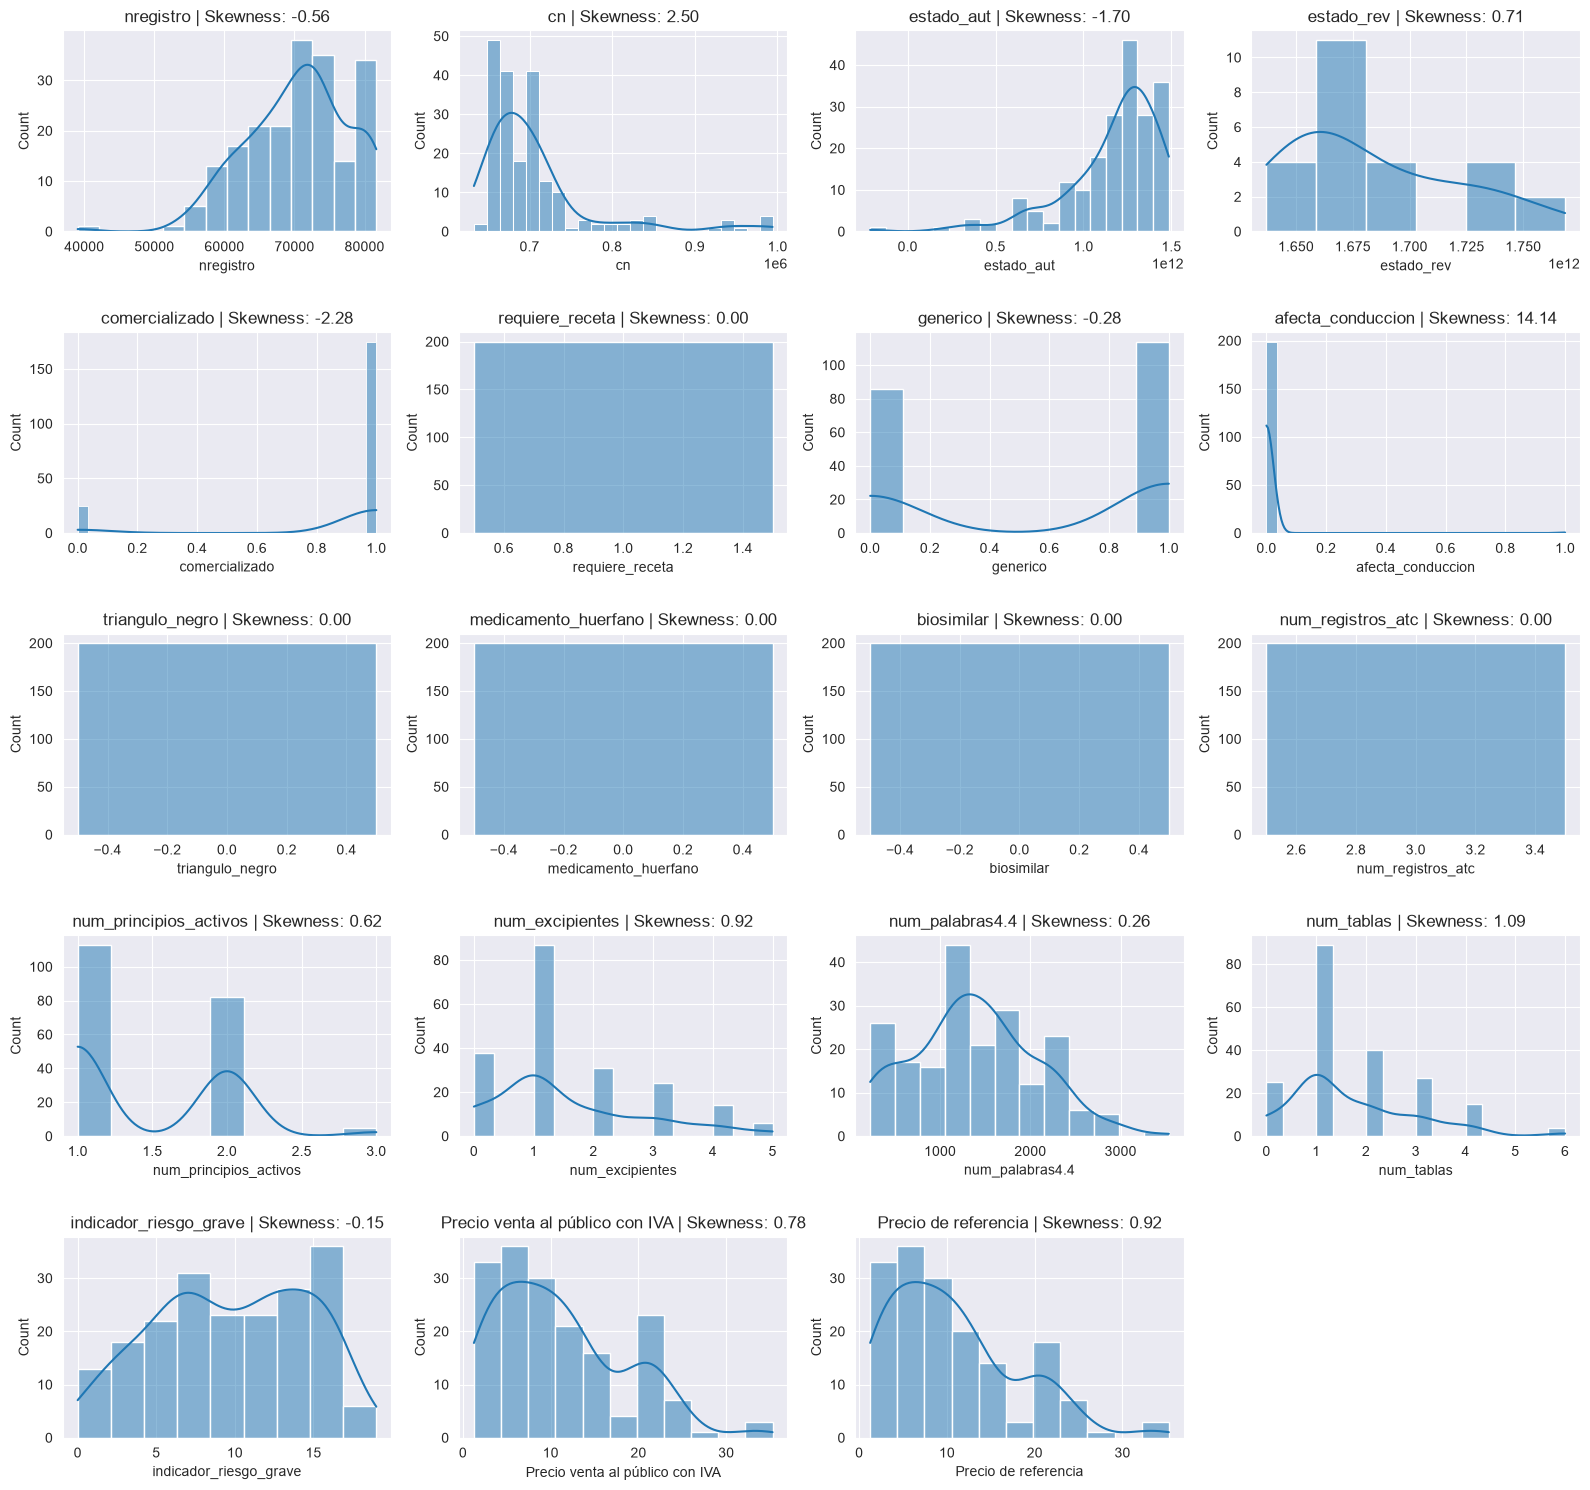

In [8]:
df = pd.read_excel("../../../data/raw/medicamentosHU3.xlsx")
print("="*30)
print(df.head())
print("="*30)
print(df.shape)
print("="*30)
print(df.info())
print("="*30)
print(df.describe().T)
print("="*30)
print(df.columns.tolist())
print("="*30)
print(df.isnull().sum())
print("="*30)
print(df.duplicated().sum())
print("="*30)

sns.set_style("darkgrid")

numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

n_cols = 4
n_rows = math.ceil(len(numerical_columns) / n_cols)

plt.figure(figsize=(16, n_rows * 3))

for idx, feature in enumerate(numerical_columns, 1):
    plt.subplot(n_rows, n_cols, idx)
    sns.histplot(df[feature], kde=True)
    plt.title(f"{feature} | Skewness: {df[feature].skew():.2f}")

plt.tight_layout()
plt.subplots_adjust(hspace=0.5)
plt.show()

# Análisis EDA

identificar la muestra: nombre

estado_aut, estado_rev?

Eliminar variables: nregistor, labcomercialziar, cn, url_html_ficha_tecnica, url_foto_materiales, precio de referencia
Data leakage: 
Variables numericas: dosis, num_registros_atc, num_principios_activos, num_registros_atc, num_excipientes, num_palabras, num_tablas, indicador_riesgo_grave, precio_venta
Varibles nominales: pactivos, labtitular, forma_farmaceutica_simplificada, vias_administracion, comercializado, requiere_receta, generico, afecta_conduccion, triangulo_negro, medicamento_huerfano, biosimilar, estado, Tratamiento de larga duración, Especial control médico
Variables ordinales:



nregistro: no aporta ninguna información útil a la hora de entrenarlo
nombre: nombre del medicamento
pactivos: principios activos
labtitular: laboratorio titular de autorización
labcomercializar: laboratorio comercialziador. Se elimina porque se importa la información con labtitular
cn: código nacional. Se elimina proque no aporta ninguna información útil
dosis: concentración. Habria que hacer una limpieza asegurar para pasarlo a integer y luego habria que pasarlo todas a la mismas unidades.
forma_farmaceutica_simplificada:
estado_aut: fecha de autorizacion. Hacer embedding?
estado_rev: fecha de revisión. Hacer embedding?
vias_administracion: Vias de administración
comercializado: Indicador binario (1 comercializado, 0 no comercialziado)
requiere_receta: Indicador binario (1 receta, 0 no receta)
generico: Indicador binario (1 generico, 0 no generico)
afecta_conducción: indicador binario(1 afecta, 0 no afecta)
triangulo_negro: indicador binario
medicamento_huermano: indicador binario
biosimilar: indicador binario
url_html_ficha_tecnica: eliminar no aporta ninguna informacion util
url_foto_materiales: eliminar no aprota ninguna informacuon util
num_registros_atc: Conteo total (longitud) de los elementos en la lista de códigos ATC
num_principios_activos:
num_excipientes
num_palabras: numero de palabras
num_tablas: numero de tablas 
indicador_riesgo_grave: numero de veces que aparece grave en el texto
estado:
precio_venta:
precio_referencia: eliminar se repite con precio_venta
Tratamiento de larga duración